In [1]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations, get_freqs, visualize_Category_hist
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient

# Data statistics

In [2]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    _,
    LesionAssessment,
    label_healthy_vs_cancer,
    label_cancer_vs_hbd,
    label_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


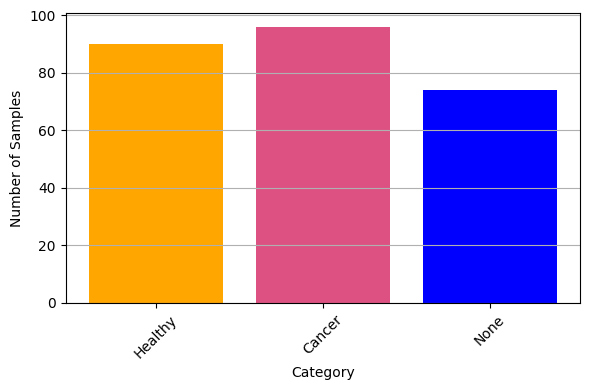

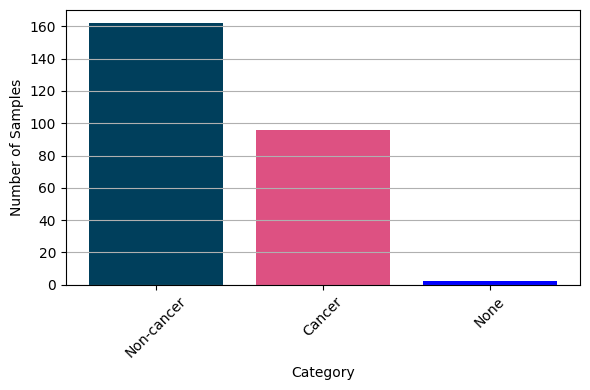

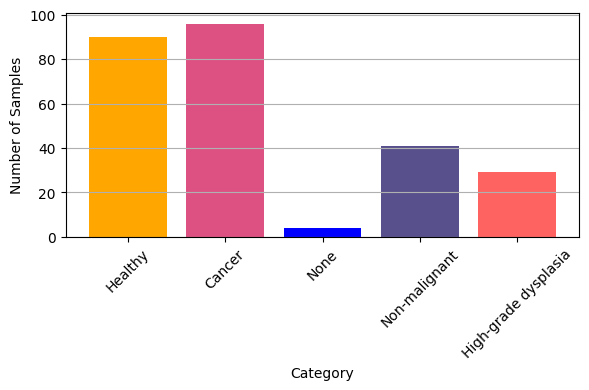

In [3]:
visualize_Category_hist(
    label_healthy_vs_cancer, s_name="results/hist_healthy_vs_cancer.pdf"
)
visualize_Category_hist(label_cancer_vs_hbd, s_name="results/hist_cancer_vs_hbd.pdf")
visualize_Category_hist(label_MC, s_name="results/hist_MC.pdf")

# Model selection

In [87]:
Fsel = "All"
Msel = "All"

class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv")

In [88]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
                  Architecture   ROC AUC    Recall  F1-score
0      DecisionTreeClassifier  0.718424  0.715342  0.715716
1  GradientBoostingClassifier  0.876471  0.808298  0.808107
2                          LR  0.853493  0.800992  0.801018
3                          RF  0.896930  0.818872  0.819065
4                         SVM  0.883983  0.836183  0.836305


/tmp/ipykernel_3652879/524524292.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_3652879/524524292.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_3652879/524524292.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


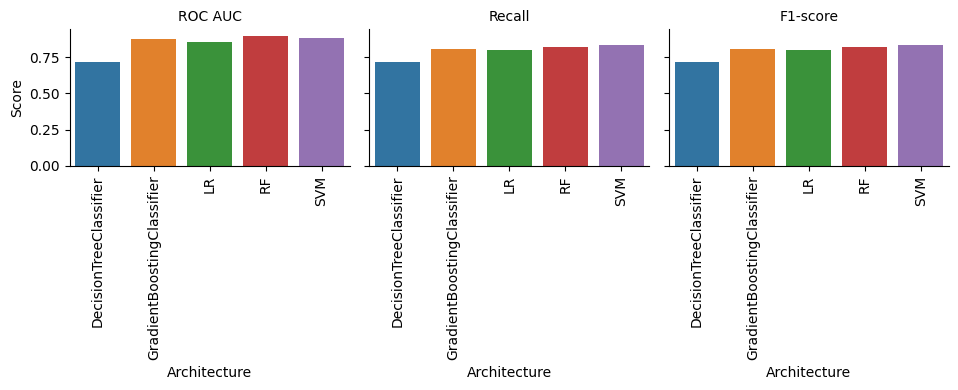

In [89]:
g = sns.catplot(
    data=df_melt,
    x="Architecture",
    y="Score",
    hue="Architecture",
    col="Metric",
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Architecture", "Score")

# Rotate x tick labels
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

# Frequency reduction

In [38]:
# class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [39]:
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

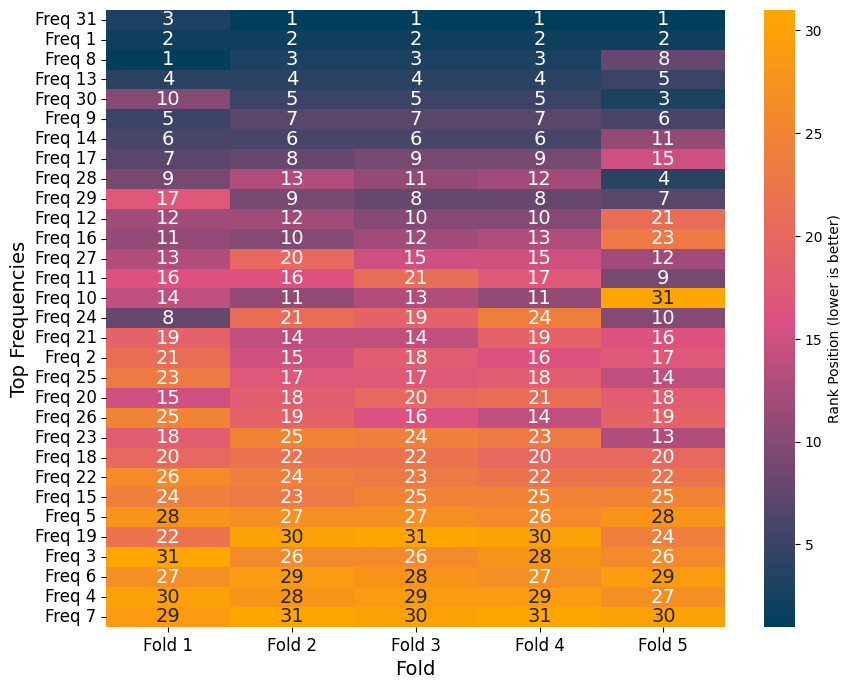

In [40]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20, class_task="unnamed"):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f+1}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}_{class_task}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31, class_task=class_task)

<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3652879/3281572220.py:22: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Number of top frequencies $\mathbf{f}_\mathrm{T}$")


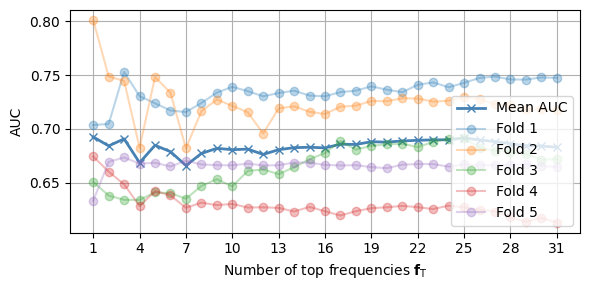

In [41]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    np.nanmean([np.array(v) for v in fold_aucs_baseline.values()], axis=0),
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of top frequencies $\mathbf{f}_\mathrm{T}$")
plt.xticks(range(1, 31 + 1, 3))
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"results/baselineaucs_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [42]:
freq_idx, freq_list = get_freqs(plot=False)

In [43]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

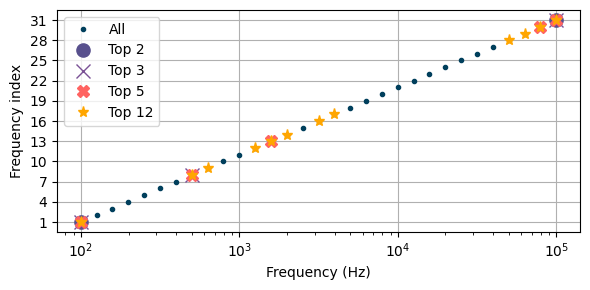

In [44]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx + 1, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2 + 1, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3 + 1, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5 + 1, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12 + 1, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.yticks(range(1, 31 + 1, 3))
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [20]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

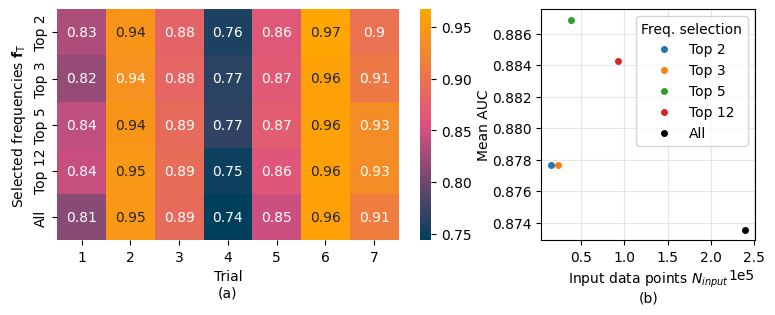

In [21]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Mean AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
        color="black" if row["Fsel"] == "All" else None,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

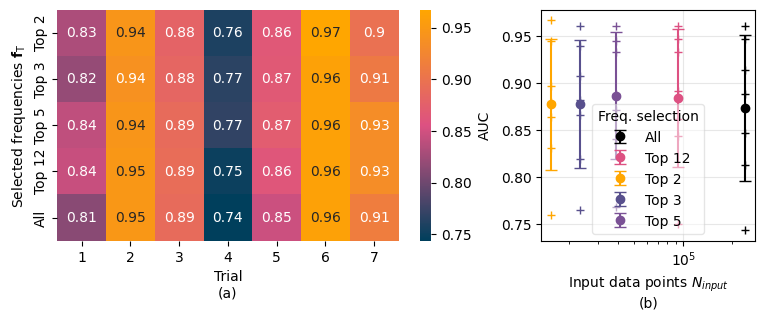

In [22]:
Fsel_map = {
    "All": "black",
    "Top 2": "#FFA600",
    "Top 3": "#58508D",
    "Top 5": "#7A5195",
    "Top 12": "#DD5182",
}

df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]
df_pivot = df_pivot.reindex(order)
sns.heatmap(df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "AUC"}, ax=ax0)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")

# right plot
ax1 = fig.add_subplot(gs[1])
df_merged = pd.merge(df_params, df_results, on="Fsel")
df_summary = (
    df_merged.groupby(["n_params", "Fsel"])["avg. ROC AUC"]
    .agg(["mean", "std"])
    .reset_index()
)
# scatter with error bars
for fsel, group in df_summary.groupby("Fsel"):
    ax1.errorbar(
        group["n_params"],
        group["mean"],
        yerr=group["std"],
        fmt="o",
        capsize=4,
        label=fsel,
        color=Fsel_map.get(fsel, None),
    )
ax1.legend()
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

for x, y, c in zip(
    df_merged["n_params"], df_merged["avg. ROC AUC"], df_merged["Fsel"].map(Fsel_map)
):
    ax1.plot(
        x,
        y,
        "+",
        color=c,
        markersize=6,
    )
ax1.set_xscale("log")
ax1.legend(title="Freq. selection", framealpha=0.5)
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [45]:
df_plot

,Fsel,n_params,avg. ROC AUC
0,Top 2,15456,0.877677
1,Top 3,23184,0.877650
2,Top 5,38640,0.886890
3,Top 12,92736,0.884273
4,All,239568,0.873544


In [48]:
df_plot["n_params"] / 239568 * 100

0      6.451613
1      9.677419
2     16.129032
3     38.709677
4    100.000000
Name: n_params, dtype: float64

In [49]:
min(df_plot["avg. ROC AUC"]), max(df_plot["avg. ROC AUC"])

(0.6502669483124267, 0.6760387768881887)

## Statistical impact of $\mathbf{f}_\mathrm{T}$ plot

In [52]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

files = glob("results/freq-analysis_*_statistics.csv")

dfs = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)
mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_hbd": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_hbd": "#FFA600",
    "MC": "#FF6361",
}
df_stats["Color"] = df_stats["Task"].map(mapping_c)
df_stats["Task"] = df_stats["Task"].map(mapping_t)

In [54]:
files

['results/freq-analysis_healthy_vs_cancer_statistics.csv',
 'results/freq-analysis_cancer_vs_hbd_statistics.csv',
 'results/freq-analysis_MC_statistics.csv',
 'results/freq-analysis_MC_ALL_statistics.csv']

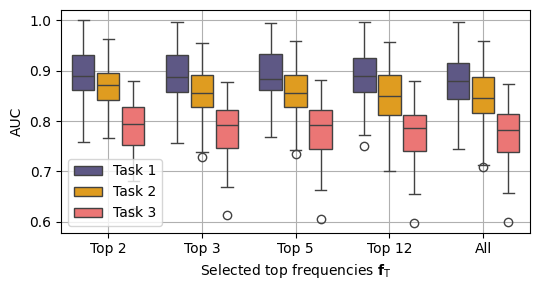

In [55]:
plt.figure(figsize=(5.5, 3))
sns.boxplot(
    data=df_stats,
    x="Fsel",
    y="auc",
    hue="Task",
    # fill=False,
    palette={
        task: color
        for task, color in zip(df_stats["Task"].unique(), df_stats["Color"].unique())
    },
    gap=0.1,
)

# sns.stripplot(
#   data=df_stats,
#   x="Fsel",
#   y="auc",
#   hue="Task",
#   dodge=True,
#   color=".3",
#   jitter=True,
#   alpha=0.7
# )
plt.ylabel("AUC")
plt.grid()
plt.xlabel(r"Selected top frequencies $\mathbf{f}_\mathrm{T}$")
plt.legend()
plt.tight_layout()
plt.savefig(f"results/freq-analysis_statistics.pdf", bbox_inches="tight")
plt.show()

# IIVV pattern reduction

In [82]:
# class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [83]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

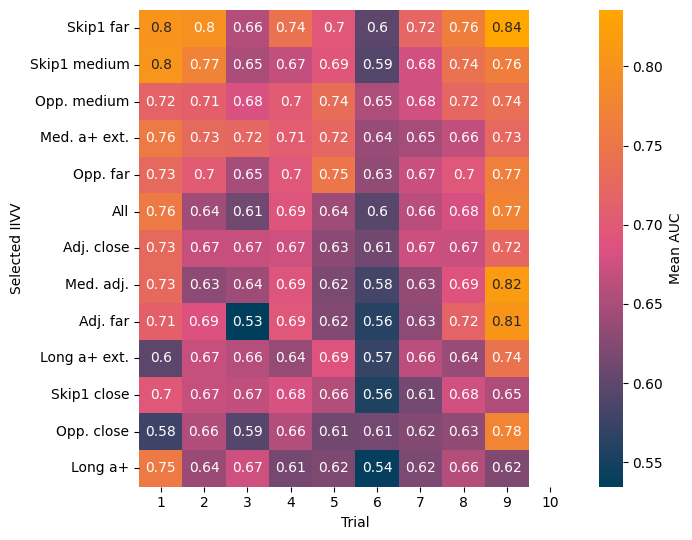

In [84]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [85]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 far       0.735378
Skip1 medium    0.707389
Opp. medium     0.703941
Med. a+ ext.    0.701401
Opp. far        0.698781
All             0.672632
Adj. close      0.672207
Med. adj.       0.669856
Adj. far        0.662692
Long a+ ext.    0.652142
Skip1 close     0.652095
Opp. close      0.637940
Long a+         0.637264
dtype: float64


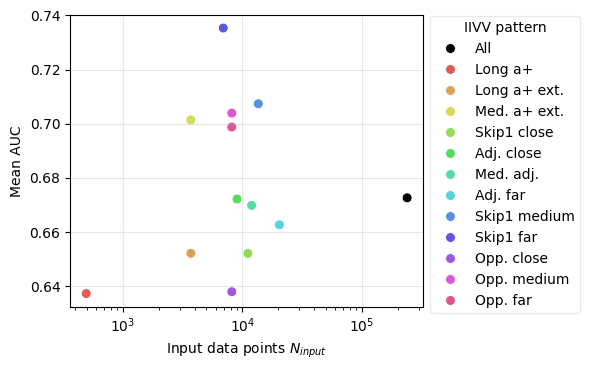

In [86]:
categories = df_plot["Mask"].unique()
base_palette = sns.color_palette(palette="hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = "black"
    else:
        palette[cat] = base_palette[i]
        i += 1

fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    palette=palette,
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Input data points $N_{input}$")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Statistical impact of IIVV maskimport numpy as np

In [1]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

files = glob("results/IIVV-analysis_*_statistics.csv")

dfs = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)
mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_hbd": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_hbd": "#FFA600",
    "MC": "#FF6361",
}
df_stats["Color"] = df_stats["Task"].map(mapping_c)
df_stats["Task"] = df_stats["Task"].map(mapping_t)

In [2]:
df_stats

,Task,IIVV,rs,auc,Color
0,Task 1,All,0,0.813462,#58508D
1,Task 1,All,0,0.882353,#58508D
2,Task 1,All,0,0.930796,#58508D
3,Task 1,All,0,0.915789,#58508D
4,Task 1,All,0,0.913495,#58508D
...,...,...,...,...,...
3895,Task 3,Opp. far,19,0.827988,#FF6361
3896,Task 3,Opp. far,19,0.763552,#FF6361
3897,Task 3,Opp. far,19,0.775554,#FF6361
3898,Task 3,Opp. far,19,0.695976,#FF6361


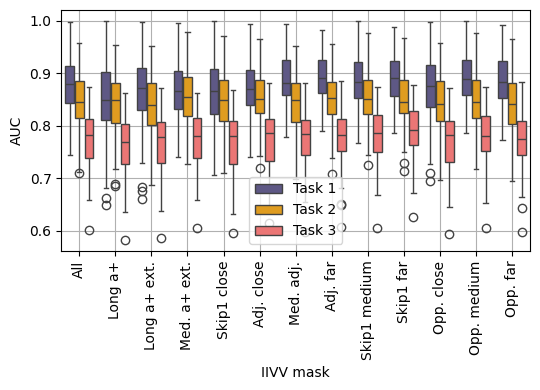

In [3]:
plt.figure(figsize=(5.5, 4))
sns.boxplot(
    data=df_stats,
    x="IIVV",
    y="auc",
    hue="Task",
    palette={
        task: color
        for task, color in zip(df_stats["Task"].unique(), df_stats["Color"].unique())
    },
    gap=0.1,
)
plt.ylabel("AUC")
plt.grid()
plt.xlabel("IIVV mask")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(f"results/IIVV-analysis_statistics.pdf", bbox_inches="tight")
plt.show()

___

# Model and parameter tuning results

- Tuning: 4 (best freq. sel) x 4 (best IIVV sel.) = 16 combinations
- Parameter tuning: SVM, RF, LR for baseline


In [1]:
import glob

import numpy as np
import pandas as pd
from toolbox.evaluation import load_top_Fsel_Msel

In [2]:
csv_files = glob.glob("results/LPOCV_tuning_*.csv")

if not csv_files:
    print("No matching file name found.")
else:
    for file in csv_files:
        try:
            df = pd.read_csv(file)
            print(f"{file}: {len(df)} Zeilen")
        except Exception as e:
            print(f"Error during loading {file}: {e}")

results/LPOCV_tuning_SVM_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_RF_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_LR_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_SVM_cancer_vs_hbd.csv: 120 Zeilen
results/LPOCV_tuning_SVM_MC.csv: 120 Zeilen
results/LPOCV_tuning_RF_cancer_vs_hbd.csv: 120 Zeilen
results/LPOCV_tuning_LR_cancer_vs_hbd.csv: 120 Zeilen
results/LPOCV_tuning_RF_MC.csv: 120 Zeilen
results/LPOCV_tuning_LR_MC.csv: 120 Zeilen


In [3]:
tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]
models = ["SVM", "RF", "LR"]

for class_task in tasks:
    # load frequency selection
    Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)

    for model in models:
        if model == models[0]:
            param_grid = {
                "kernel": ["linear", "poly", "rbf", "sigmoid"],
                "C": np.logspace(
                    -3, 3, 7, dtype=float
                ),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
            }

        elif model == models[1]:
            param_grid = {
                "n_estimators": [100, 300, 500, 800],
                "max_depth": [510, 20, None],
                "max_features": ["sqrt", "log2"],
                "min_samples_split": [2, 5, 10],
                "min_samples_leaf": [1, 2, 4],
            }
        elif model == models[2]:
            param_grid = {
                "C": [0.01, 0.1, 1, 10, 100],
                "max_iter": [100, 1000, 10_000],
            }
        keys = list(param_grid.keys())

        print("\n%----------------------------%")
        print(f"\t{class_task}")
        print(f"\t{model}")

        df = pd.read_csv(f"results/LPOCV_tuning_{model}_{class_task}.csv")

        print("Top Frequencies")
        for Fsel, val in Freq_sel.items():
            print("\t", Fsel, ":", val)
        print("Top IIVVs")
        for Msel in Mask_sel.keys():
            print("\t", Msel)
        print("\n")
        df["hpt_combinations"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in keys]), axis=1
        )

        df["Fsel_Msel"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in ["Fsel", "Msel"]]), axis=1
        )

        result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
        print(result)

        for col in ["hpt_combinations"]:
            print(f"\nColumn: {col}")
            print(df[col].value_counts())

        # get most important tuning comb
        top_hpt = df["hpt_combinations"].value_counts().idxmax()
        print(f"\nMost counted hpt_combinations: {top_hpt}")

        fsel_msel_counts = (
            df.loc[df["hpt_combinations"] == top_hpt, "Fsel_Msel"]
            .value_counts()
            .reset_index()
            .rename(columns={"index": "Fsel_Msel", "Fsel_Msel": "count"})
        )

        print(f"\nRelated Fsel_Msel etries for {top_hpt}")
        print(fsel_msel_counts)

        print("%----------------------------%")


%----------------------------%
	healthy_vs_cancer
	SVM
Top Frequencies
	 Top 2 : [30  0]
	 Top 3 : [30  0 12]
	 Top 5 : [30  0 12 27 29]
	 Top 12 : [30  0 12 27 29  8 13 28 16 10 26 11]
Top IIVVs
	 Med. adj.
	 Adj. far
	 Skip1 far
	 Opp. medium


  hpt_combinations   val AUC
0     linear_0.001  0.901352
1      linear_0.01  0.899914
2       linear_0.1  0.908242
3        poly_0.01  0.902310
4         poly_0.1  0.899432
5         poly_1.0  0.912754
6          rbf_0.1  0.897542
7          rbf_1.0  0.902525
8         rbf_10.0  0.907243
9      sigmoid_0.1  0.892857

Column: hpt_combinations
hpt_combinations
linear_0.001    39
rbf_10.0        34
rbf_1.0         26
poly_0.1        25
rbf_0.1         10
linear_0.01      9
poly_0.01        5
poly_1.0         5
linear_0.1       4
sigmoid_0.1      3
Name: count, dtype: int64

Most counted hpt_combinations: linear_0.001

Related Fsel_Msel etries for linear_0.001
             count  count
0   Top 5_Adj. far      9
1   Top 6_Adj. far      8
2   Top 

## Pattern and Parameters

In [58]:
from toolbox.evaluation import load_top_Fsel_Msel

In [59]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]

for class_task in class_tasks:
    print(class_task, "\n")
    Freq_sel, _ = load_top_Fsel_Msel(class_task)
    print(Freq_sel["Top 12"] + 1)

healthy_vs_cancer 

[31  1 28 13 30  9 29 14 17 27 11 12]
cancer_vs_hbd 

[31  1 13 30  8  9 14 12 17 28 29 16]
MC 

[31  1  8 13 30  9 14 17 28 29 12 16]


## ROC plots

In [26]:
glob("results/ROC*.npz")

['results/ROC_default_healthy_vs_cancer_SVM_baseline.npz',
 'results/ROC_default_healthy_vs_cancer_RF_baseline.npz',
 'results/ROC_default_healthy_vs_cancer_LR_baseline.npz',
 'results/ROC_default_cancer_vs_hbd_SVM_baseline.npz',
 'results/ROC_default_cancer_vs_hbd_RF_baseline.npz',
 'results/ROC_default_cancer_vs_hbd_LR_baseline.npz',
 'results/ROC_default_MC_SVM_baseline.npz',
 'results/ROC_default_MC_RF_baseline.npz',
 'results/ROC_default_MC_LR_baseline.npz',
 'results/ROC_tuned_healthy_vs_cancer_SVM.npz',
 'results/ROC_tuned_healthy_vs_cancer_RF.npz',
 'results/ROC_tuned_healthy_vs_cancer_LR.npz',
 'results/ROC_tuned_cancer_vs_hbd_SVM.npz',
 'results/ROC_tuned_cancer_vs_hbd_RF.npz',
 'results/ROC_tuned_cancer_vs_hbd_LR.npz',
 'results/ROC_tuned_MC_SVM.npz',
 'results/ROC_tuned_MC_RF.npz',
 'results/ROC_tuned_MC_LR.npz',
 'results/ROC_default_healthy_vs_cancer_SVM.npz',
 'results/ROC_default_healthy_vs_cancer_RF.npz',
 'results/ROC_default_healthy_vs_cancer_LR.npz',
 'results/ROC_d

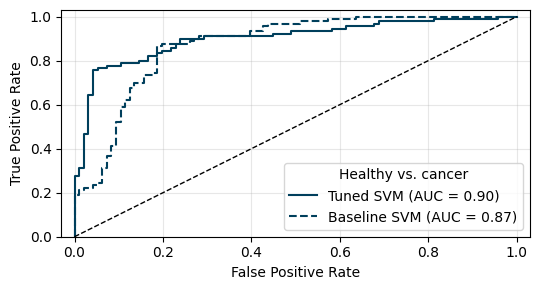

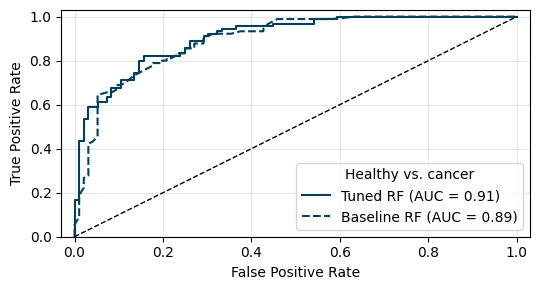

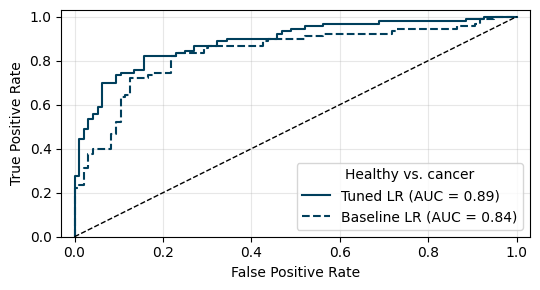

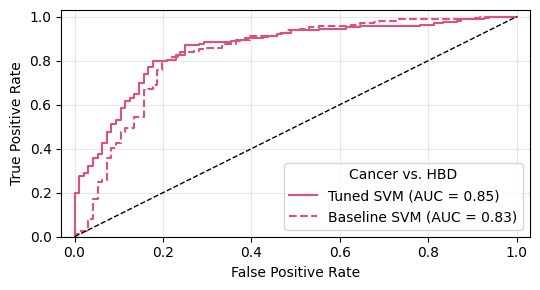

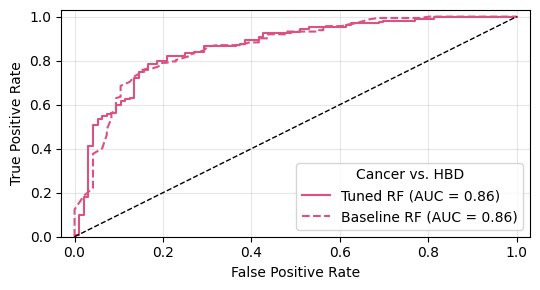

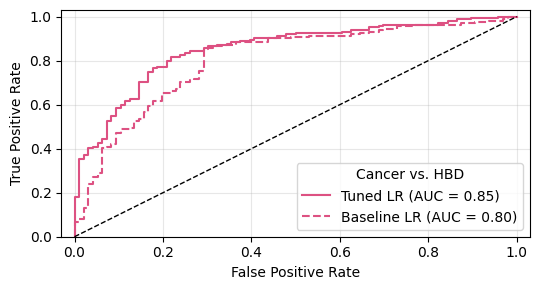

In [32]:
models = ["SVM", "RF", "LR"]
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd"]

label_roc_plot = {
    "healthy_vs_cancer": "Healthy vs. cancer",
    "cancer_vs_hbd": "Cancer vs. HBD",
}


for class_task in class_tasks:
    for model in models:
        tuned = np.load(
            f"results/ROC_tuned_{class_task}_{model}.npz", allow_pickle=True
        )
        baseline = np.load(
            f"results/ROC_default_{class_task}_{model}_baseline.npz", allow_pickle=True
        )

        s_name = f"results/ROC_baseline_tuned_{class_task}_{model}_combined.pdf"

        plt.figure(figsize=(5.5, 3))
        plt.plot(
            tuned["fpr"],
            tuned["tpr"],
            color=tuned["color"].tolist(),
            label=f"Tuned {model} (AUC = {tuned["roc_auc"]:.2f})",
        )
        plt.plot(
            baseline["fpr"],
            baseline["tpr"],
            "--",
            color=baseline["color"].tolist(),
            label=f"Baseline {model} (AUC = {baseline["roc_auc"]:.2f})",
        )
        plt.plot([0, 1], [0, 1], "k--", linewidth=1)
        plt.xlim([-0.03, 1.03])
        plt.ylim([0.0, 1.03])
        plt.grid()
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend(loc="lower right", title=label_roc_plot[class_task])
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")

## Timings

In [112]:
cp = {
    "Baseline": "#FF6361",
    "Tuned": "#A1D99B",
}

  model_type model class_task    timing
0      Tuned   SVM     Task 1  0.001215
1      Tuned   SVM     Task 1  0.001252
2      Tuned   SVM     Task 1  0.001093
3      Tuned   SVM     Task 1  0.001166
4      Tuned   SVM     Task 1  0.001091


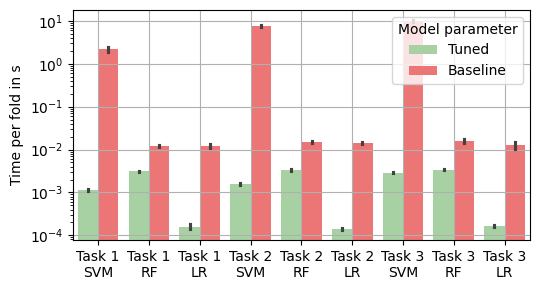

In [113]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

label_roc_plot = {
    "healthy_vs_cancer": "Task 1",
    "cancer_vs_hbd": "Task 2",
    "MC": "Task 3",
}

files = glob.glob("results/timings_default*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_default_param_models.pdf", bbox_inches="tight")

  model_type model class_task    timing
0      Tuned   SVM     Task 1  0.001287
1      Tuned   SVM     Task 1  0.001241
2      Tuned   SVM     Task 1  0.001193
3      Tuned   SVM     Task 1  0.001044
4      Tuned   SVM     Task 1  0.001348


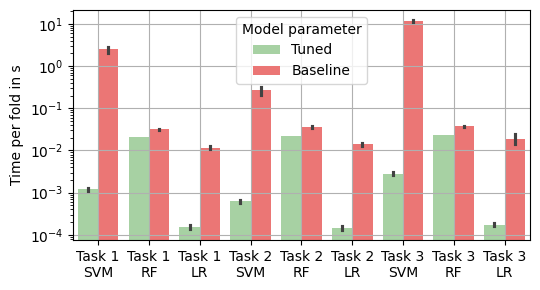

In [114]:
files = glob.glob("results/timings_tuned*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_tuned_param_models.pdf", bbox_inches="tight")

  model_type model class_task    timing
0      Tuned   SVM     Task 1  0.001287
1      Tuned   SVM     Task 1  0.001241
2      Tuned   SVM     Task 1  0.001193
3      Tuned   SVM     Task 1  0.001044
4      Tuned   SVM     Task 1  0.001348


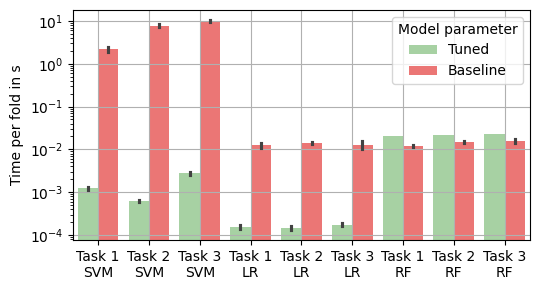

In [115]:
files_1 = glob.glob("results/timings_tuned*_SVM.npz")
files_3 = glob.glob("results/timings_tuned*_RF.npz")
files_2 = glob.glob("results/timings_tuned*_LR.npz")
files_4 = glob.glob("results/timings_default*baseline.npz")
files = files_1 + files_2 + files_3 + files_4

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig(
    "results/timings_for_tuned_vs_default_param_models.pdf", bbox_inches="tight"
)

## Visualize IIVV mask

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from toolbox import Masking

In [2]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [3]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [42]:
mask.prints = False


def plot_Mask(mask, mode="horizontal", title=None, s_name=None):

    if mode == "horizontal":
        plt.figure(figsize=(6, 2.2))
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 1],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 2],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 3],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.xlabel("IIVV index")
        plt.ylabel("Electrode no.")
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()
    if mode == "vertical":
        plt.figure(figsize=(2, 6))
        plt.plot(
            mask.IIVV[mask.mask][:, 0],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 1],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 2],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 3],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.ylabel("IIVV index")
        plt.xlabel("Electrode no.")
        # plt.yticks(ticks=np.arange(len(mask.mask)),labels=np.arange(len(mask.mask)))
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()

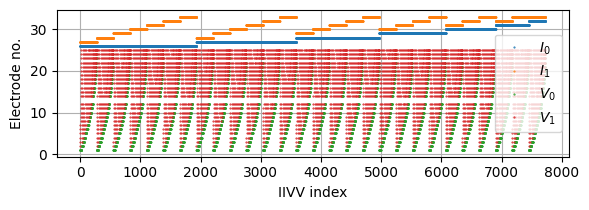

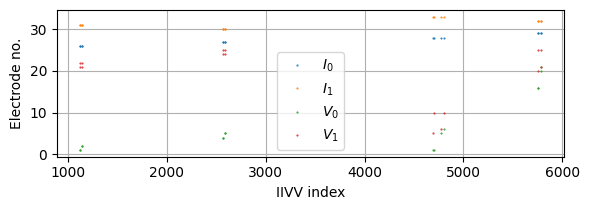

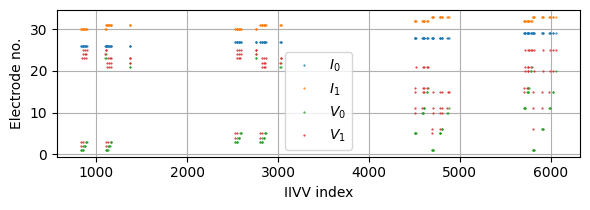

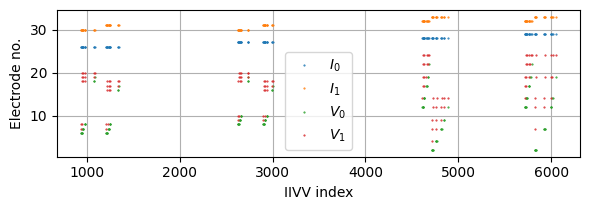

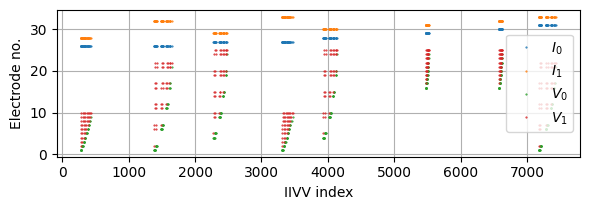

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
type(dd) <class 'list'>
[3, 4, 5, 8, 9, 10, 13, 14, 15]
type(dd) <class 'list'>
[4, 5, 9, 10, 14, 15, 19, 20, 24, 25]
type(dd) <class 'list'>
[13, 14, 15, 18, 19, 20, 23, 24, 25]
type(dd) <class 'list'>
[16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
type(dd) <class 'list'>
[11, 12, 13, 16, 17, 18, 21, 22, 23]
type(dd) <class 'list'>
[1, 2, 6, 7, 11, 12, 16, 17, 21, 22]
type(dd) <class 'list'>
[1, 2, 3, 6, 7, 8, 11, 12, 13]
type(dd) <class 'list'>


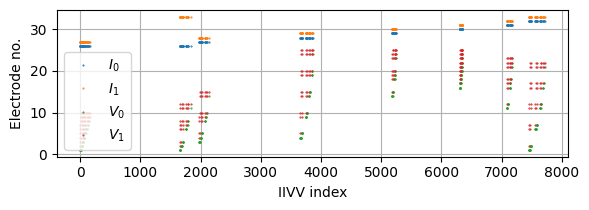

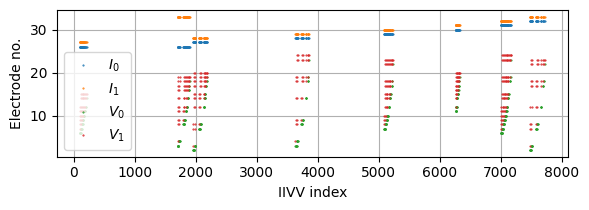

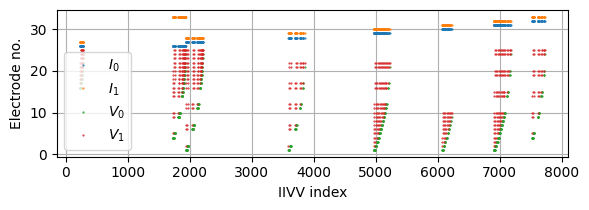

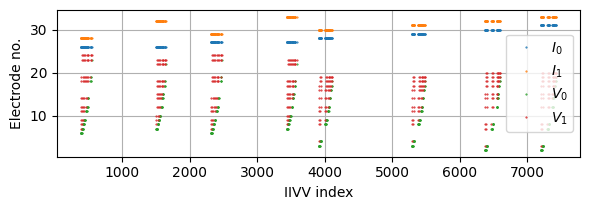

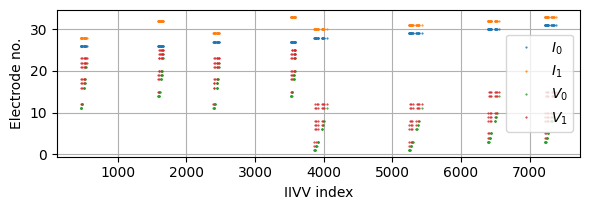

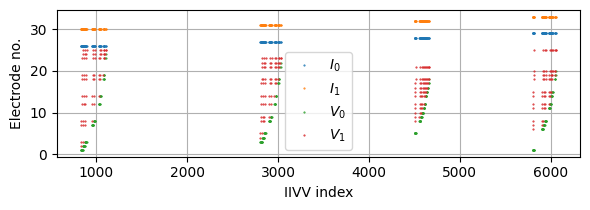

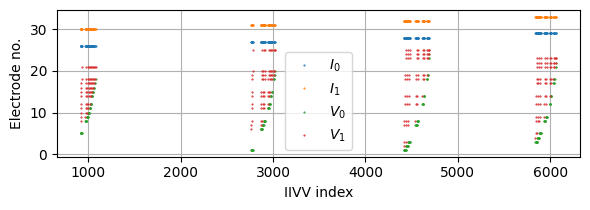

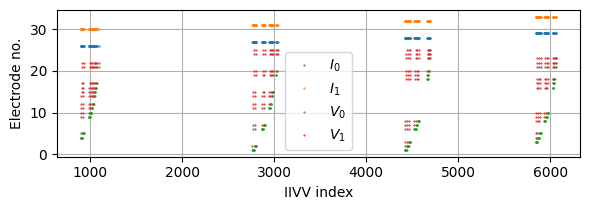

In [43]:
for Msel in Mask_sel:
    mask.IIVV_mask(Mask_sel[Msel], plot=False)
    plot_Mask(
        mask,
        mode="horizontal",
        title=None,
        s_name=f"results/IIVV_pattern_{Mask_sel[Msel]}.pdf",
    )

In [57]:
caption_names = {
    "all": r"\textit{All}",
    "vv_long_across": r"\textit{Long a+}",
    "vv_long_across_extended": r"\textit{Long a+ ext.}",
    "vv_medium_across_extended": r"\textit{Med. a+ ext.}",
    "vv_distance_close_skip_1": r"\textit{Skip1 far}",
    "adjacent_close": r"\textit{Opp. close}",
    "vv_distance_medium_adj": r"\textit{Opp. medium}",
    "adjacent_far": r"\textit{Opp. far}",
    "skip1_medium": r"\textit{Adj. close}",
    "skip1_far": r"\textit{Skip1 close}",
    "opposite_close": r"\textit{Med. adj.}",
    "opposite_medium": r"\textit{Skip1 medium} ",
    "opposite_far": r"\textit{Adj. far}",
}

with open("results/IIVVlatex.txt", "w", encoding="utf-8") as f:
    for values in Mask_sel.values():
        f.write(r"\begin{figure}[H]" + "\n")
        f.write(r"    \centering" + "\n")
        f.write(
            r"    \includegraphics[width=0.8\columnwidth]{figures/IIVVmasks/IIVV_pattern_"
            + f"{values}"
            + r".pdf}"
            + "\n"
        )
        f.write(r"    \caption{IIVV mask " + f"{caption_names[values]}" + r"}" + "\n")
        f.write(r"    \label{appendix:fig:IIVV:" + f"{values}" + r"}" + "\n")
        f.write(r"\end{figure}" + "\n\n")

___